In [1]:
import os, sys, pathlib
ROOT = pathlib.Path.cwd()
while not (ROOT / "config" / "params.yaml").exists(): ROOT = ROOT.parent
os.chdir(ROOT); sys.path.insert(0, str(ROOT / "src"))
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import Image, display
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)
from gfr import config; cfg = config.load()

# 02 - Empirical fragility curves
Ordered-probit model with latent regional PGA:  P(DG>=k) = Phi((ln PGA_r - ln m_k,s)/beta_s).
The survey subset has no ground motion, so regional ln PGA is inferred and anchored to a mean/spread set in `config/params.yaml` (`fragility.*`).

In [2]:
from gfr import fragility as F
df = pd.read_csv('data/processed/gorkha_clean.csv.gz')
cfg['fragility']['n_boot'] = 0        # set to 60 for bootstrap bands (scripts/03 does this)
r = F.fit_all(df, cfg, bootstrap=False)
r['table'].round(3)

,stratum,n_buildings,median_DG2plus_g,median_DG3_g,beta,DG3_extrapolated
0,CM_BRICK|1-2fl,12766,0.115,0.857,0.935,False
1,CM_BRICK|3+fl,2748,0.118,0.563,0.688,False
2,CM_STONE|all,3273,0.064,0.430,0.794,False
3,MM_BRICK|1-2fl,6860,0.076,0.295,0.568,False
4,MM_BRICK|3+fl,8543,0.075,0.306,0.456,False
5,MM_STONE|1-2fl,154232,0.061,0.247,0.598,False
6,MM_STONE|3+fl,46657,0.052,0.255,0.614,False
7,RC_E|1-2fl,1544,0.357,5.078,1.389,True
8,RC_E|3+fl,1121,0.327,1.210,0.908,True
9,RC_MIX|1-2fl,5627,0.060,1.006,1.733,True


In [3]:
F.weighted_fit_metrics(r['cells'])   # in-sample fit on region x stratum cells

{'DG2_rmse': 0.051950324292387016,
 'DG2_r2': 0.8862183978180362,
 'DG3_rmse': 0.04200963898268822,
 'DG3_r2': 0.9681874464593172}

In [4]:
r['regions'].round(3).sort_values('pga_g', ascending=False).head(10)

,geo_level_1_id,pga_g,n_buildings
17,17,0.459,21779
18,18,0.390,3146
27,27,0.296,12519
21,21,0.291,14863
8,8,0.270,19080
11,11,0.252,8204
3,3,0.251,7515
10,10,0.224,22079
28,28,0.223,252
7,7,0.210,18994


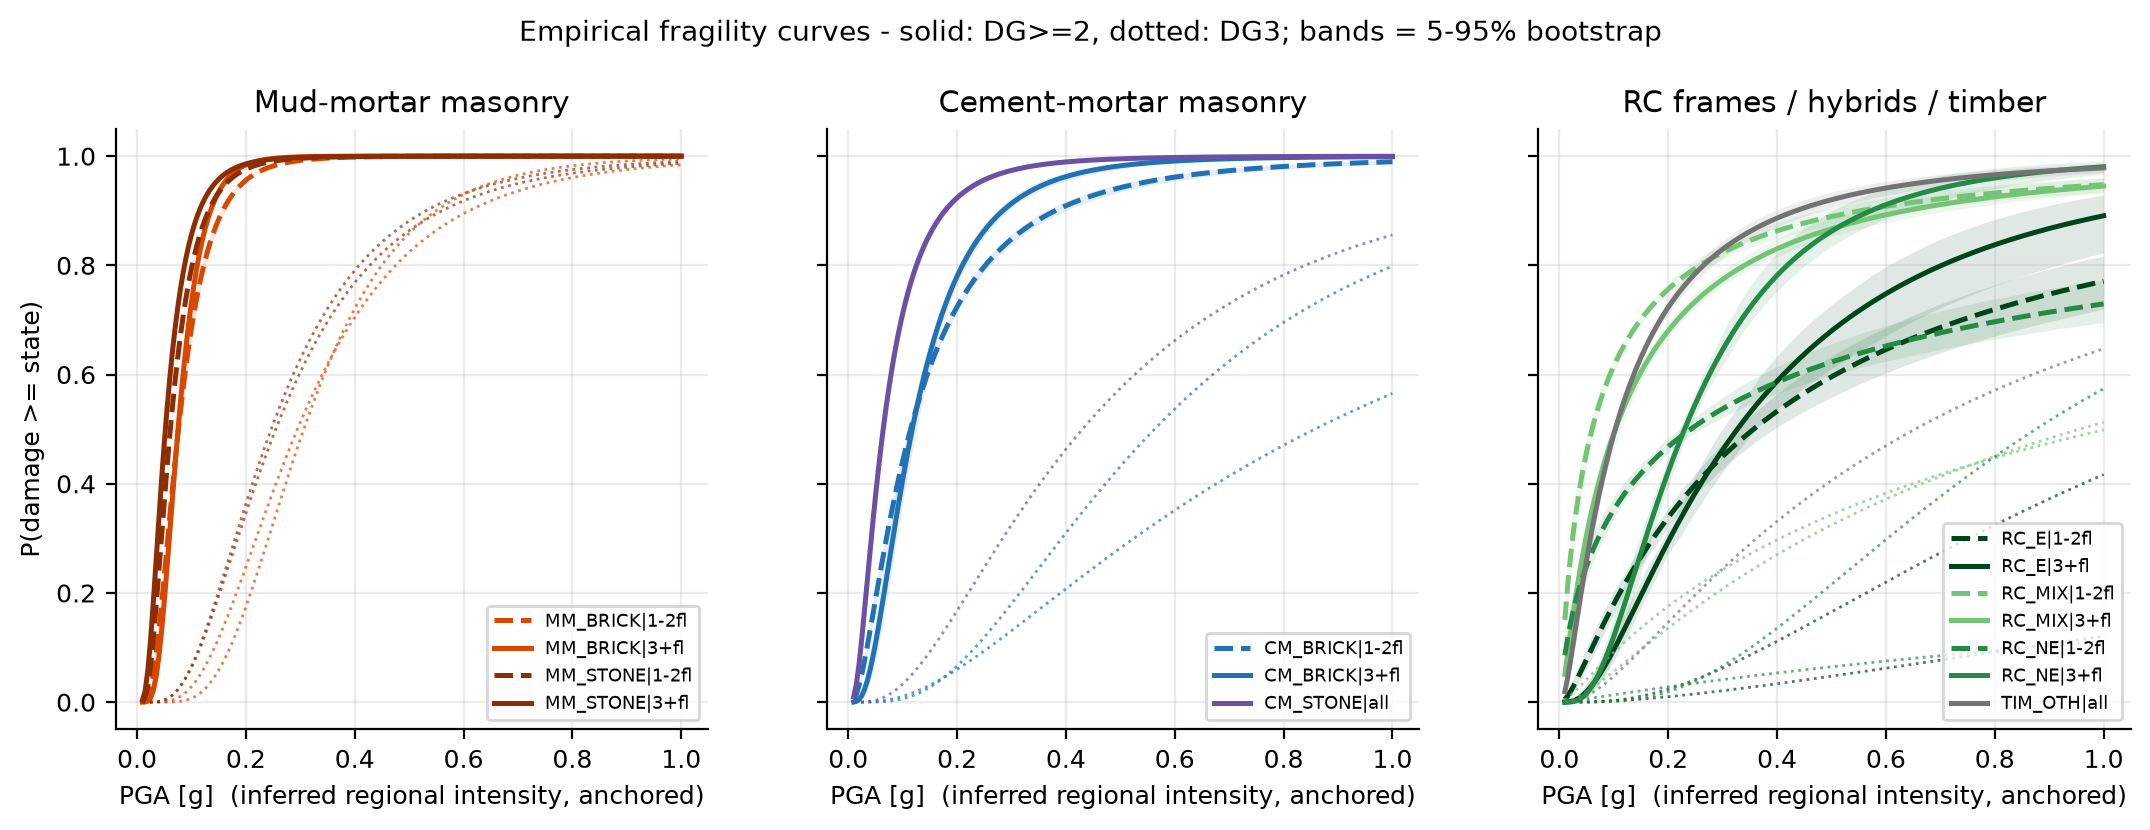

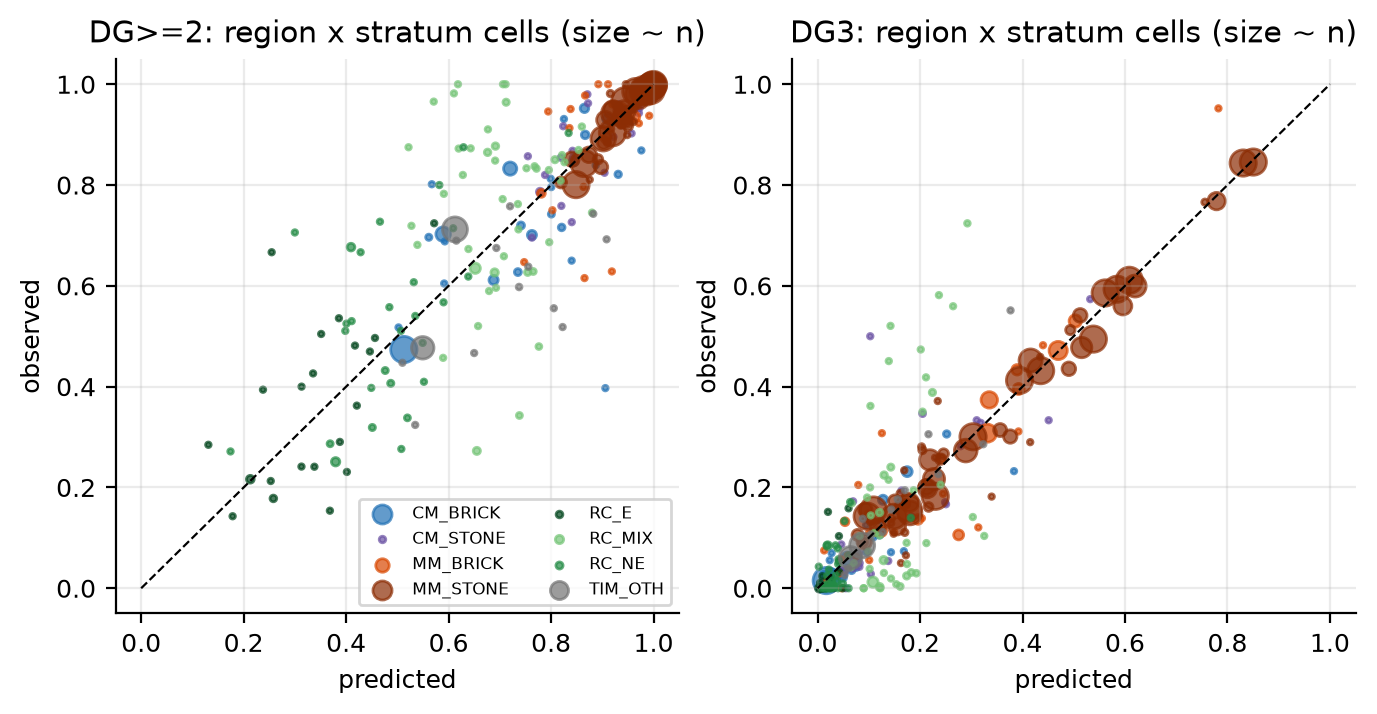

In [5]:
display(Image('results/figures/02_empirical_fragility.png')); display(Image('results/figures/03_fragility_calibration.png'))

### Logistic variant (statsmodels) and odds ratios

In [ ]:
pd.read_csv('results/tables/logistic_fragility.csv').head(12)

: 

In [ ]:
pd.read_csv('results/tables/logit_odds_ratios.csv').query("outcome=='DG>=2'").round(2)

### Sensitivity to the ground-motion anchor
Medians scale almost linearly with the anchor; relative ranking of classes does not.

In [8]:
pd.read_csv('results/tables/anchor_sensitivity.csv').query("stratum=='MM_STONE|1-2fl'")

,im_ref_g,sigma_ln,stratum,median_DG2plus_g,median_DG3_g,beta
0,0.15,0.3,MM_STONE|1-2fl,0.0617,0.1755,0.4489
4,0.15,0.4,MM_STONE|1-2fl,0.0459,0.1849,0.5985
8,0.15,0.5,MM_STONE|1-2fl,0.0341,0.1948,0.7481
12,0.20,0.3,MM_STONE|1-2fl,0.0822,0.2340,0.4489
16,0.20,0.4,MM_STONE|1-2fl,0.0611,0.2466,0.5985
20,0.20,0.5,MM_STONE|1-2fl,0.0455,0.2598,0.7481
24,0.30,0.3,MM_STONE|1-2fl,0.1233,0.3510,0.4489
28,0.30,0.4,MM_STONE|1-2fl,0.0917,0.3698,0.5985
32,0.30,0.5,MM_STONE|1-2fl,0.0682,0.3897,0.7481
